In [2]:
import numpy as np

import matplotlib
import matplotlib.pyplot as plt

from astropy.io import fits
import glob
from scipy import stats
from scipy.stats import norm
import os
from scipy.stats import linregress

This is a lab that focuses on calibrations in photometry and spectroscopy. We also took a couple science images (Bode's Galaxy for my group) and turned it into a "pretty picture" by calibrating and stacking it into a colored image with different filters.

4.1) We will first learn how to make a master bias that is useful in subtracting the eletronical offset predetermined by the settings of the camera.
I will first define a function that takes in sets of frames (dark, bias, flat, ect.) and output its master file by stacking them up and computing the median.

In [3]:
def fits_file_stack (fits_files):
    ### input: takes in several files of same category
    ### output: master and the flattened pixels

    #get files
    files = sorted(glob.glob(fits_files))
    print(f"Found {len(files)} files")

    #read
    frames = []
    for f in files:
        with fits.open(f) as hdul:
            data = hdul[0].data.astype(float)
            frames.append(data)

    #stack into np array
    stack = np.array(frames)
    print("Stack shape:", stack.shape)

    # Compute master bias
    master = np.median(stack, axis=0)

    #Flatten pixels
    pixels = master.flatten()

    return master, pixels, stack

master_bias, pixel_bias, bias_stack= fits_file_stack("lab_1/Bias_0s_0C_20260209_*.fits")


Found 10 files
Stack shape: (10, 1044, 1562)


Here we plot a histogram of the distribution of counts by flattening the master bias into a 1d array and using matplotlib.

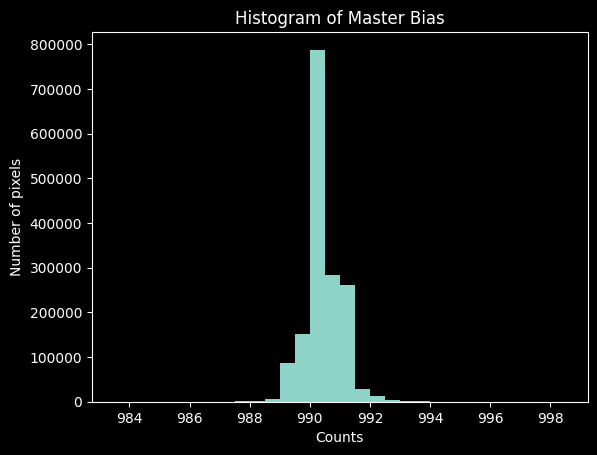

In [4]:
#plot histogram for master_bias

plt.figure()
plt.hist(pixel_bias, bins=30)
plt.ylabel("Number of pixels")
plt.xlabel("Counts")
plt.title("Histogram of Master Bias")
plt.show()


In [5]:
#try to detect hot/cold pixels
pixel_bias_median = np.median(pixel_bias)
pixel_bias_std = np.std(pixel_bias)

lower, upper = pixel_bias_median - 5*pixel_bias_std, pixel_bias_median + 5*pixel_bias_std

outliers = np.sum((pixel_bias < lower) | (pixel_bias > upper))

print(f"Number of pixels outside 5-sigma: {outliers}")
print(pixel_bias_median)
print(5*pixel_bias_std)


Number of pixels outside 5-sigma: 1312
990.0
3.041661015021515


#4.1.a) We notice that there is 1312 pixels outside of the 5-sigma range. However, since the counts of each pixel is so tightly knitted, 5 standard deviation is less than .003% deviation from the mean. Therefore, there is no hot pixels --> no need to derive a cut.


#4.1.b) Read noise is the statistical fluctuations when a CCD camera converts a electron to a digital unit. We will not plot a Gaussian over the histogram to calculate the read noise by finding the standard deviation. We then multiply the readout noise (ADU) by the gain to convert the unit to electrons.

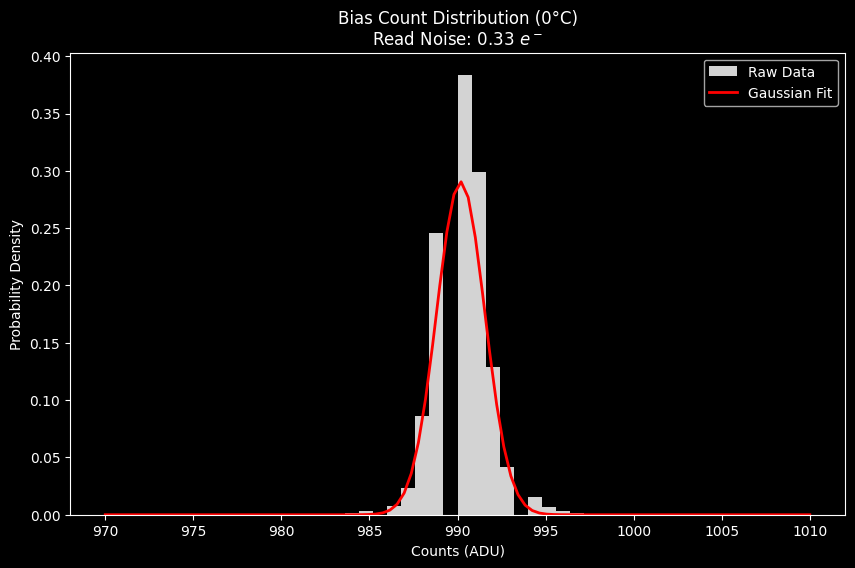

Mean (Bulk): 990.18 ADU
Read Noise (ADU): 1.37
Camera Gain: 0.2428629249 e-/ADU
Read Noise (Electrons): 0.33 e-


In [6]:
# 1. Load data and Header
hdul = fits.open("lab_1/Bias_0s_0C_20260209_164545113.fits")
data = hdul[0].data.astype(float).flatten()
gain = hdul[0].header['EGAIN']

# 2. Define the bulk range
# We limit the data to avoid the 'perfectly non-Gaussian' tails
med = np.median(data)
std_initial = np.std(data)

# 3 sigma cut
lower_limit = med - 3 * std_initial
upper_limit = med + 3 * std_initial
bulk_data = data[(data >= lower_limit) & (data <= upper_limit)]

# 3. Calculate "Clean" stats from the Bulk
clean_mean = np.mean(bulk_data)
clean_std_adu = np.std(bulk_data)
read_noise_electrons = clean_std_adu * gain

# 4. Plotting the Histogram and the Gaussian Overplot
plt.figure(figsize=(10, 6))


count, bins, ignored = plt.hist(data, bins=50, range=(med-20, med+20),
                                density=True, color='lightgray', label='Raw Data')

# Generate the Gaussian curve based on our 'Clean' stats
x = np.linspace(med-20, med+20, 100)
gaussian_curve = norm.pdf(x, clean_mean, clean_std_adu)

# Overplot the Gaussian
plt.plot(x, gaussian_curve, 'r-', lw=2, label=f'Gaussian Fit')

plt.title(f"Bias Count Distribution (0°C)\nRead Noise: {read_noise_electrons:.2f} $e^-$")
plt.xlabel("Counts (ADU)")
plt.ylabel("Probability Density")
plt.legend()
plt.show()

# 5. Final Results
print(f"Mean (Bulk): {clean_mean:.2f} ADU")
print(f"Read Noise (ADU): {clean_std_adu:.2f}")
print(f"Camera Gain: {gain} e-/ADU")
print(f"Read Noise (Electrons): {read_noise_electrons:.2f} e-")

In [7]:
#4.2.1)


Dark frames are used to detect dark current - unwanted electric signals caused by thermal energy. Bias frames are included in a dark frame so when calibrating a science image, need only to subtract the master dark. In this section, we will find the hot pixels - pixels with high dark current - by:
1) Create master dark
2) Find the standard deviation
3) Use the standard deviation to detect pixels with abnormally high counts (more than 5 $\sigma$ than the median)

In [8]:
master_dark, pixel_dark, dark_stack=fits_file_stack("lab_1/Dark_15s_*_20260209_*.fits")

Found 10 files
Stack shape: (10, 1044, 1562)


In [9]:
#try to detect hot pixels for the stack
dark_median = np.median(master_dark, axis=0)
dark_std = np.std(master_dark)
hot_mask = master_dark > (dark_median + 5 * dark_std)
hot_pixel_coords = np.argwhere(hot_mask)
outliers_dark = np.sum(master_dark > dark_median + 5 * dark_std)
print(f"Found {len(hot_pixel_coords)} permanent hot pixels.")
print(f"Number of pixels outside 5-sigma: {outliers_dark}")
print(dark_median)
print(5*dark_std)
print(hot_pixel_coords)

Found 52 permanent hot pixels.
Number of pixels outside 5-sigma: 52
[990. 990. 990. ... 990. 990. 990.]
24.370043784658314
[[  23 1004]
 [  29  393]
 [  48 1502]
 [  67  366]
 [  86 1206]
 [ 112  414]
 [ 165  710]
 [ 177  772]
 [ 192  144]
 [ 232 1075]
 [ 245 1043]
 [ 313 1547]
 [ 327  683]
 [ 339  876]
 [ 342  448]
 [ 347 1065]
 [ 356  876]
 [ 379  863]
 [ 396   51]
 [ 446 1133]
 [ 467  727]
 [ 486  440]
 [ 514 1322]
 [ 518   13]
 [ 543 1002]
 [ 567 1281]
 [ 636  926]
 [ 645  454]
 [ 648  614]
 [ 670  541]
 [ 672 1404]
 [ 691  756]
 [ 698   77]
 [ 709  800]
 [ 710  353]
 [ 716 1239]
 [ 763 1408]
 [ 796 1474]
 [ 801 1374]
 [ 828  760]
 [ 858 1374]
 [ 870  601]
 [ 880  143]
 [ 881  645]
 [ 911 1034]
 [ 911 1472]
 [ 933 1242]
 [1002 1452]
 [1010  183]
 [1023  273]
 [1025  608]
 [1041  481]]


Here we show why taking multiple darks and taking median to create a master dark is necessary. As you can see, there are more detected "hot pixels" (54 compared to 53) on a individual dark frame. These are mostly caused by cosmic rays that get disregarded when we take the median.

In [10]:
#Suffice to check for 1 individual dark frame with same exposure and temp to see if there is a difference in hot pixels.
master_dark_ind, pixel_dark_ind, dark_stack_ind=fits_file_stack("lab_1/Dark_15s_0C_20260209_175217.fits")
dark_median = np.median(master_dark_ind, axis=0)
dark_std = np.std(master_dark_ind)
hot_mask = master_dark_ind > (dark_median + 5 * dark_std)
hot_pixel_coords = np.argwhere(hot_mask)
print(f"Found {len(hot_pixel_coords)} hot pixels.")


Found 1 files
Stack shape: (1, 1044, 1562)
Found 54 hot pixels.


We want to see the rate of the dark currents per second. To do that, we first need to calculate the statistical and systematic uncertainty.

In [11]:
dark_files= sorted(glob.glob("lab_1/Dark_15s_*_20260209_*.fits"))

In [12]:
results = []

for file in dark_files:
    with fits.open(file) as hdul:
        data = hdul[0].data.astype(float).flatten() # Flatten for easier indexing

        # BULK STATISTICS (3-Sigma)
        med = np.median(data)
        std_init = np.std(data)

        mask_3s = (data > med - 3*std_init) & (data < med + 3*std_init)
        bulk_3s = data[mask_3s]

        mean_3s = np.mean(bulk_3s)
        std_3s = np.std(bulk_3s)
        n_pixels = len(bulk_3s)

        # 1. Statistical Uncertainty
        stat_unc = std_3s / np.sqrt(n_pixels)

        # 2. Systematic Uncertainty (using a 5-sigma range for comparison)
        mask_5s = (data > med - 5*std_init) & (data < med + 5*std_init)
        mean_5s = np.mean(data[mask_5s])
        sys_unc = abs(mean_3s - mean_5s )

        results.append({
            'file': file,
            'mean': mean_3s,
            'stat_unc': stat_unc,
            'sys_unc': sys_unc,
            'std_3s': std_3s,
        })
# --- PRINT RESULTS ---
print(f"{'Filename':<35} | {'Mean':<8} | {'Stat Unc':<10} | {'Sys Unc':<10} | STD")
print("-" * 75)
for r in results:
    print(f"{r['file']:<35} | {r['mean']:<8.3f} | {r['stat_unc']:<10.5f} | {r['sys_unc']:<10.5f} |{r['std_3s']:<10.2f}")

Filename                            | Mean     | Stat Unc   | Sys Unc    | STD
---------------------------------------------------------------------------
lab_1\Dark_15s_-1C_20260209_175055.fits | 990.276  | 0.00121    | 0.00081    |1.55      
lab_1\Dark_15s_0C_20260209_175006.fits | 990.280  | 0.00121    | 0.00088    |1.55      
lab_1\Dark_15s_0C_20260209_175023.fits | 990.270  | 0.00121    | 0.00073    |1.55      
lab_1\Dark_15s_0C_20260209_175038.fits | 990.276  | 0.00121    | 0.00074    |1.55      
lab_1\Dark_15s_0C_20260209_175128.fits | 990.277  | 0.00121    | 0.00094    |1.55      
lab_1\Dark_15s_0C_20260209_175145.fits | 990.273  | 0.00121    | 0.00076    |1.55      
lab_1\Dark_15s_0C_20260209_175201.fits | 990.269  | 0.00121    | 0.00078    |1.54      
lab_1\Dark_15s_0C_20260209_175217.fits | 990.277  | 0.00121    | 0.00075    |1.55      
lab_1\Dark_15s_0C_20260209_175233.fits | 990.266  | 0.00121    | 0.00081    |1.54      
lab_1\Dark_15s_1C_20260209_175112.fits | 990.276  | 

We see that the systematic uncertainty dominates because the data is very clean with only 52 warm pixel.

We now plot the mean counts against exposure time (with the error bars) and perform linear regression (so we have a slope to work with).

Filename                            | Mean     | Total Unc 
------------------------------------------------------------
lab_1\Dark_10s_0C_20260209_164941.fits | 990.277  | 0.00141   
lab_1\Dark_120s_0C_20260209_165656.fits | 991.348  | 0.00175   
lab_1\Dark_15s_0C_20260209_175006.fits | 990.280  | 0.00150   
lab_1\Dark_15s_0C_20260209_175023.fits | 990.270  | 0.00142   
lab_1\Dark_15s_0C_20260209_175038.fits | 990.276  | 0.00142   
lab_1\Dark_15s_0C_20260209_175128.fits | 990.277  | 0.00153   
lab_1\Dark_15s_0C_20260209_175145.fits | 990.273  | 0.00143   
lab_1\Dark_15s_0C_20260209_175201.fits | 990.269  | 0.00144   
lab_1\Dark_15s_0C_20260209_175217.fits | 990.277  | 0.00143   
lab_1\Dark_15s_0C_20260209_175233.fits | 990.266  | 0.00146   
lab_1\Dark_20s_0C_20260209_165105.fits | 990.369  | 0.00179   
lab_1\Dark_30s_0C_20260209_165135.fits | 990.463  | 0.00210   
lab_1\Dark_30s_0C_20260209_165917.fits | 990.474  | 0.00204   
lab_1\Dark_30s_0C_20260209_165948.fits | 990.464  | 0.00201

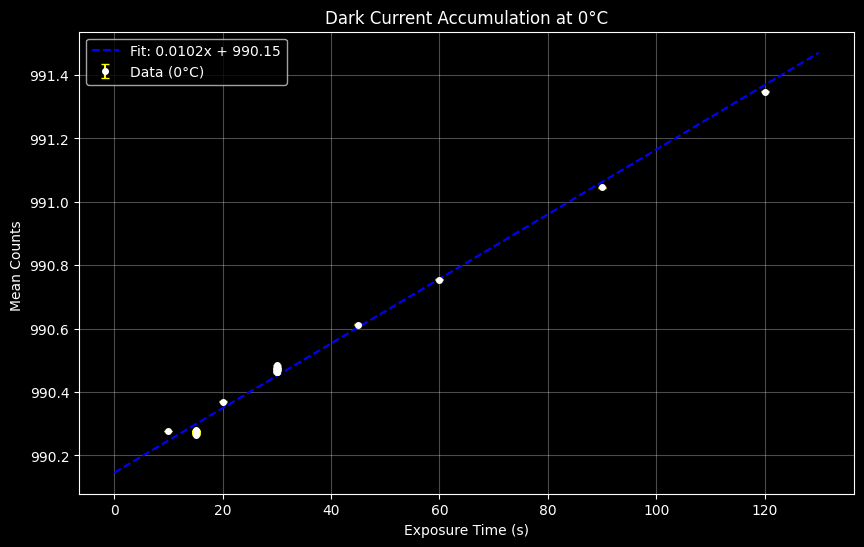


Dark Current Rate: 0.010193 DC/s
Bias Intercept: 990.1454 C


In [13]:
# 1. Grab all 0C files automatically
import os
from scipy.stats import linregress
all_0C_files = sorted(glob.glob("lab_1/Dark_*_0C_20260209_*.fits")) + sorted(glob.glob("lab_1/Dark_*_1C_20260209_*.fits")) +sorted(glob.glob("lab_1/Dark_*_-1C_20260209_*.fits"))

plot_times = []
plot_means = []
plot_errors = []

print(f"{'Filename':<35} | {'Mean':<8} | {'Total Unc':<10}")
print("-" * 60)

for file in all_0C_files:
    with fits.open(file) as hdul:
        data = hdul[0].data.astype(float).flatten()

        # CALCULATION (3-sigma for mean, 5-sigma for sys)
        med = np.median(data)
        std_init = np.std(data)

        # 3-sigma (The Bulk)
        m3 = (data > med - 3*std_init) & (data < med + 3*std_init)
        mean_3s = np.mean(data[m3])
        stat_unc = np.std(data[m3]) / np.sqrt(len(data[m3]))

        # 5-sigma (For Systematic)
        m5 = (data > med - 5*std_init) & (data < med + 5*std_init)
        mean_5s = np.mean(data[m5])
        sys_unc = abs(mean_3s - mean_5s)

        total_unc = np.sqrt(stat_unc**2 + sys_unc**2)

        # DATA EXTRACTION
        # 1. Get just the filename
        base_name = os.path.basename(file)

        # 2. Split by underscore and grab the second part ('120s')
        time_str = base_name.split('_')[1]

        # 3. Remove the 's' and convert to float
        time = float(time_str.replace('s', ''))

        plot_times.append(time)
        plot_means.append(mean_3s)
        plot_errors.append(total_unc)

        print(f"{file.split('/')[-1]:<35} | {mean_3s:<8.3f} | {total_unc:<10.5f}")

# 2. LINEAR REGRESSION
slope, intercept, r_val, p_val, std_err = linregress(plot_times, plot_means)

# 3. PLOTTING
plt.figure(figsize=(10, 6))
plt.errorbar(plot_times, plot_means, yerr=plot_errors, fmt='o', color='white',
             ecolor='yellow', capsize=3, markersize=4, label='Data (0°C)')

# Fit line
t_range = np.linspace(0, max(plot_times) + 10, 100)
plt.plot(t_range, slope * t_range + intercept, 'b--',
         label=f'Fit: {slope:.4f}x + {intercept:.2f}')

plt.xlabel('Exposure Time (s)')
plt.ylabel('Mean Counts ')
plt.title('Dark Current Accumulation at 0°C')
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

print(f"\nDark Current Rate: {slope:.6f} DC/s")
print(f"Bias Intercept: {intercept:.4f} C")

We now plot a graph showing the residuals of the data points relative to the linear regression. By observation, we see that it is good fit. After comparing with the manufactuer's specification, there is a 0.001 difference.

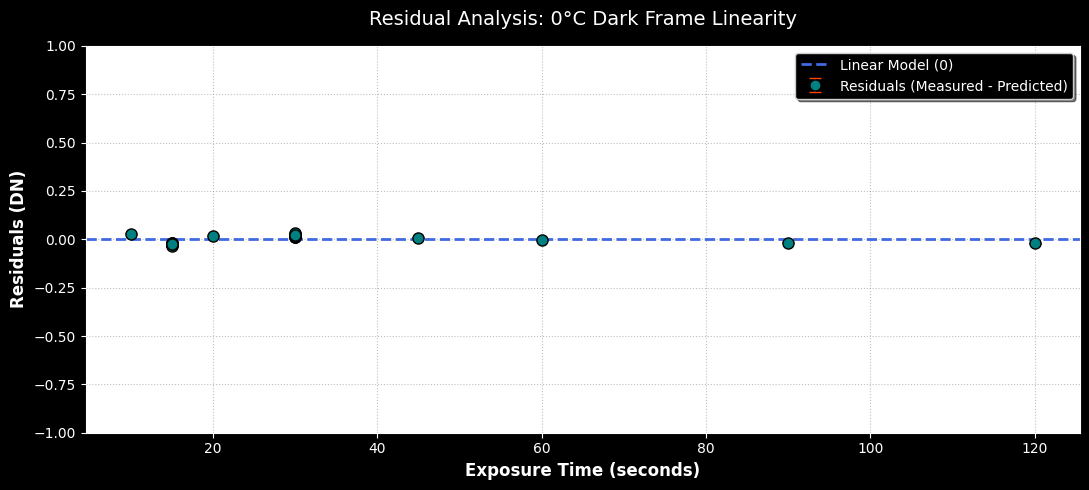

In [14]:
import matplotlib.pyplot as plt
import numpy as np

#CALCULATE RESIDUALS
#Convert numpy arrays
x_data = np.array(plot_times)
y_data = np.array(plot_means)
y_errors = np.array(plot_errors)

# Calculate the difference between actual data and the linear model prediction
y_predicted = (slope * x_data) + intercept
residuals = y_data - y_predicted

plt.figure(figsize=(11, 5))
ax = plt.axes()
ax.set_facecolor("white")

# Plot residuals

plt.errorbar(x_data, residuals, yerr=y_errors, fmt='o',
             color='teal',
             ecolor='orangered',
             elinewidth=1.5,
             capsize=4,
             markersize=8,
             markeredgecolor='black',
             label='Residuals (Measured - Predicted)')


plt.axhline(0, color='royalblue', linestyle='--', linewidth=2, label='Linear Model (0)')

#FORMATTING
plt.xlabel('Exposure Time (seconds)', fontsize=12, fontweight='bold')
plt.ylabel('Residuals (DN)', fontsize=12, fontweight='bold')
plt.title('Residual Analysis: 0°C Dark Frame Linearity', fontsize=14, pad=15)

plt.grid(True, linestyle=':', color='gray', alpha=0.5)
plt.legend(loc='best', frameon=True, shadow=True)

plt.tight_layout()
plt.ylim(-1, 1)
plt.show()

In [15]:

camera_gain = 0.2428629249  # unit: e-/DN
dark_current_e = (slope * camera_gain)

#~.0015
manufacturer_spec = 0.0015

print(f"Dark Current Analysis (0°C)    ")
print(f"Measured Slope:       {slope:.4f}")
print(f"Calculated Rate:      {dark_current_e:.4f} e-/pixel/s")
print(f"Manufacturer Spec:    {manufacturer_spec:.4f} e-/pixel/s")

diff = ((dark_current_e - manufacturer_spec) / manufacturer_spec) * 100
print(f"Percentage Deviation: {diff:.2f}%")

Dark Current Analysis (0°C)    
Measured Slope:       0.0102
Calculated Rate:      0.0025 e-/pixel/s
Manufacturer Spec:    0.0015 e-/pixel/s
Percentage Deviation: 65.03%


**We estimate the dark current rate for another temperature.**

In [16]:
master_bias_10c, pixel_bias_10c, bias_stack_10c= fits_file_stack('lab_1/Bias_0s_10C_20260209_171100459.fits')

Found 1 files
Stack shape: (1, 1044, 1562)


In [17]:
file_10c = "lab_1/Dark_120s_10C_20260209_171148.fits"

with fits.open(file_10c) as hdul:
    data_10c = hdul[0].data.astype(float).flatten()

    # 3-sigma clipping to find the 'bulk' mean
    med_10c = np.median(data_10c)
    std_10c = np.std(data_10c)
    mask = (data_10c > med_10c - 3*std_10c) & (data_10c < med_10c + 3*std_10c)
    mean_10c = np.mean(data_10c[mask])

# Assuming 'bias_mean' is your calculated mean from the 0s Bias frames
rate_dn_s = (mean_10c - np.mean(master_bias_10c)) / 120.0
rate_e_s = rate_dn_s * 0.24286

print(f"10°C Mean Counts: {mean_10c:.4f} DN")
print(f"10°C Dark Current: {rate_e_s:.6f} e-/pixel/s")

10°C Mean Counts: 993.6668 DN
10°C Dark Current: 0.007065 e-/pixel/s


The rate is significantly higher due to a higher temperature. A higher temperature --> more thermal charge --> extra charge accumulation

4.3.1) We want to get our master flat field by first taking the median of the set of flat fields and then dividing by its median. The reason we divide by the median is to get a ratio that signifies pixel sensitivity and vignetting.

In [18]:
master_flat, pixel_flat, flat_stack = fits_file_stack('lab_1/Flat_B_15s_*_20260209_*fits')
norm_master_flat= master_flat/ np.median(master_flat)
output_filename = 'lab_1/norm_Master_Flat_B_15s.fits'
hdu = fits.PrimaryHDU(norm_master_flat)
hdu.writeto(output_filename, overwrite=True)
print(f"Master Flat saved as: {output_filename}")

Found 10 files
Stack shape: (10, 1044, 1562)
Master Flat saved as: lab_1/norm_Master_Flat_B_15s.fits


4.3.2) The darker portions are about ~.96 value and the brighter portions are about ~1.25 value --> darker portion receive ~76% of the light.

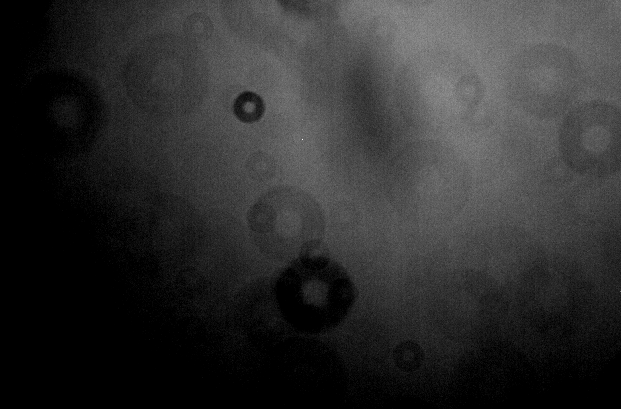

4.3.3) If we use the relative magnitude formula and plug in the percentages of light as the flux,
$$\Delta m = -2.5 \log_{10} \left( \frac{F_{\text{corner}}}{F_{\text{center}}} \right)$$
$$\Delta m = -2.5 \log_{10}(0.76)$$$$\Delta m \approx -2.5 \times (-0.119)$$$$\Delta m \approx 0.298$$

4.3.4) We plot histogram of the counts of the flat field against the number of pixels. By observation, there is no dead pixels.

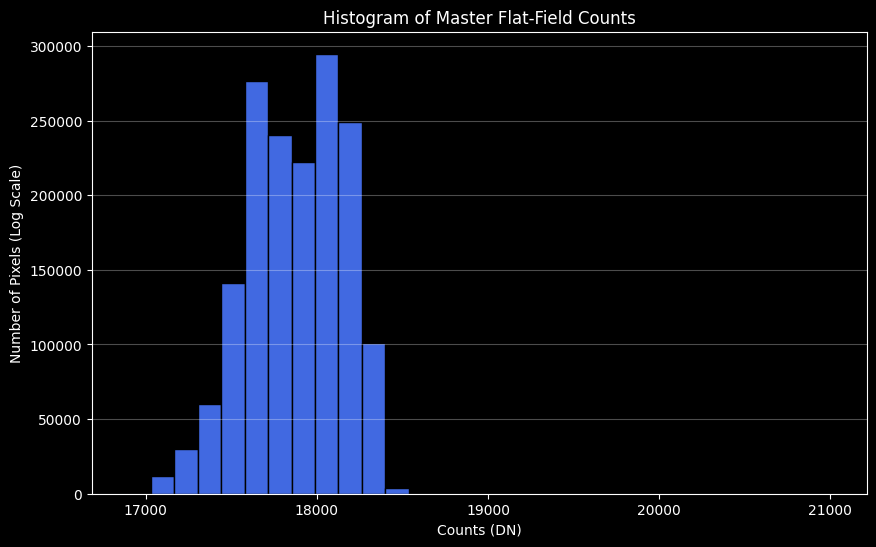

In [19]:
plt.figure(figsize=(10, 6))
# Using a log scale on the y-axis makes it much easier to see dead pixels
plt.hist(pixel_flat, bins=30, color='royalblue', edgecolor='black')
plt.title('Histogram of Master Flat-Field Counts')
plt.xlabel('Counts (DN)')
plt.ylabel('Number of Pixels (Log Scale)')
plt.grid(axis='y', alpha=0.3)
plt.show()

4.3.4) Flat fields must be taken on the same day. One thing that flat fields detect is dust spots on the telescope. Therefore, if one change the telescope or even change the filter, the dust patterns will not (usually) be the same.



4.4.1) Next we start our spectroscopic calibration. We start by obtaining the corresponding darks for the arc lamp frame and flat frames (based on exposure time). Then we subtract the corresponding darks from the flat and arc to get rid of the bias and dark currents.

In [20]:
master_flat_dark_spect, pixel_flat_dark_spect, flat_dark_spect_stack =fits_file_stack('Spectroscopy/dark_1sec_covered_*.fits')
master_arc_dark, pixel_arc_dark, arc_dark_stack = fits_file_stack("Spectroscopy/dark_60sec_covered_*.fits")
master_flat_spect, pixel_flat_spect, flat_spect_stack = fits_file_stack('Spectroscopy/flats_1sec_*.fits')

Found 5 files
Stack shape: (5, 1044, 1562)
Found 3 files
Stack shape: (3, 1044, 1562)
Found 10 files
Stack shape: (10, 1044, 1562)


In [21]:
calibrated_flat_spect = master_flat_spect - master_flat_dark_spect
arc_frame = fits.open('Spectroscopy/neon_light_spectrum_4x4_0C_60sec.fits')[0].data
calibrated_arc= arc_frame - master_arc_dark

4.4.2) The brightest line is the biggest split --> 3rd spectra is the 50 $\mu$ slit

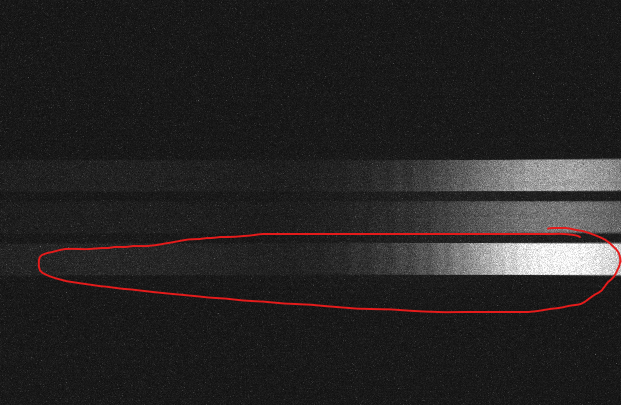

4.4.3) We want to focus on the 50 $\mu$ so we crop the image and take median of each column. This is so we can plot the 1-d flat field values against the pixel positions.

In [22]:
for i in range(1, 11):   # 1 through 10
    filename = f"Spectroscopy/flats_1sec_{i}.fits"

    with fits.open(filename) as hdul:
        data = hdul[0].data

        cropped = data[352:430, 0:1562]

        fits.writeto(f"cropped_spect_flats/cropped_flats_{i}.fits",
                     cropped,
                     overwrite=True)

print("Done.")

Done.


In [23]:
master_cropped_flat, pixel_cropped_flat, flat_spect_stack = fits_file_stack('cropped_spect_flats/cropped_flats_*.fits')

Found 10 files
Stack shape: (10, 78, 1562)


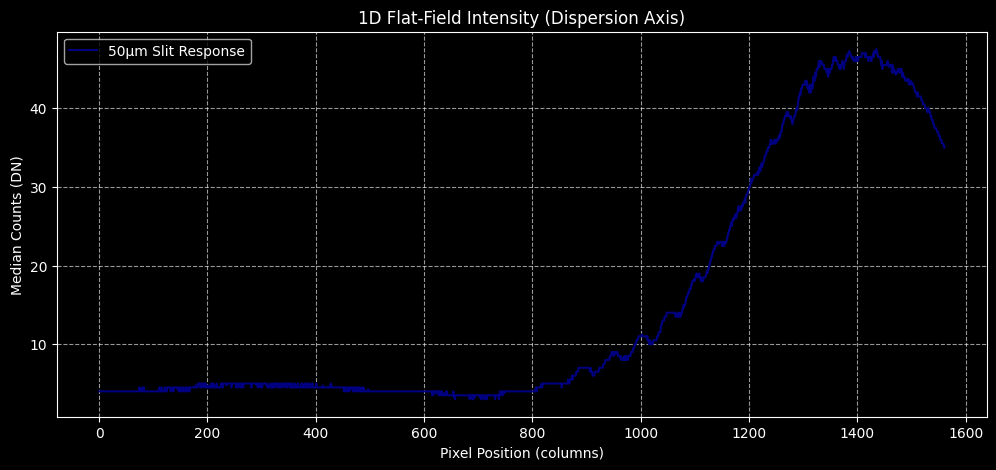

In [24]:
# axis=0 is the vertical (spatial) axis.
# Collapsing it leaves us with 1 value per column.
flat_1d = np.median(master_cropped_flat, axis=0)

# Create an array of pixel indices for the x-axis
pixel_indices = np.arange(len(flat_1d))

# 2. Plotting the 1D Profile
plt.figure(figsize=(12, 5))
plt.plot(pixel_indices, flat_1d, color='navy', label='50µm Slit Response')
plt.title('1D Flat-Field Intensity (Dispersion Axis)')
plt.xlabel('Pixel Position (columns)')
plt.ylabel('Median Counts (DN)')
plt.grid(True, linestyle='--', alpha=0.6)
plt.legend()
plt.show()

4.4.4) We normalize the flat field to combat the possibility of the intrinsic spectrum of the lamp interfering with the flat field. We normalize by fitting a 1d polynomial and dividing the raw master flat by the fit.
The raw master flat gets brighter towards the right side but the normalized one has a more uniformed brightness from left to right.

RAW:


Normalized:


The following code fits a 7th order polynomial, normalizes the flat and saves the file.

In [51]:
# Save the original raw master
hdu_raw = fits.PrimaryHDU(master_cropped_flat)
hdu_raw.writeto('master_flat_50um_RAW.fits', overwrite=True)

# Create the 1D trend and normalize
x = np.arange(len(flat_1d))
coeffs = np.polyfit(x, flat_1d, 7) # 7th order polynomial
smooth_fit = np.polyval(coeffs, x)

# Normalize: divide the 2D image by the 1D trend
normalized_flat = master_cropped_flat / smooth_fit

# Save the normalized version
hdu_norm = fits.PrimaryHDU(normalized_flat)
hdu_norm.writeto('master_flat_50um_NORM.fits', overwrite=True)

print("Files saved: 'master_flat_50um_RAW.11fits' and 'master_flat_50um_NORM.fits'")

Files saved: 'master_flat_50um_RAW.11fits' and 'master_flat_50um_NORM.fits'


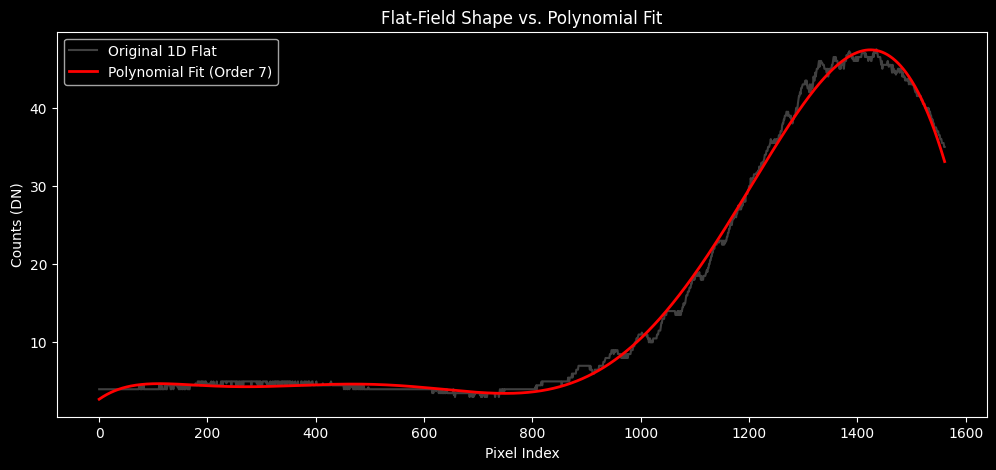

In [52]:
plt.figure(figsize=(12, 5))
plt.plot(x, flat_1d, label='Original 1D Flat', color='gray', alpha=0.5)
plt.plot(x, smooth_fit, label='Polynomial Fit (Order 7)', color='red', lw=2)
plt.title("Flat-Field Shape vs. Polynomial Fit")
plt.xlabel("Pixel Index")
plt.ylabel("Counts (DN)")
plt.legend()
plt.show()

4.4.5)
When cut out the lamp spectrum of the 50 $\mu$m slit and deduct the master dark from it and apply the normalized flat.


In [53]:
cropped_arc_raw= fits.open('Spectroscopy/neon_light_spectrum_4x4_0C_60sec.fits')[0].data[352:430, 0:1562].astype(float)
dark_arc_cropped = master_arc_dark[352:430, 0:1562]
calibrated_crop_arc= cropped_arc_raw - dark_arc_cropped
normalized_calibrated_crop_arc = calibrated_crop_arc / normalized_flat

4.4.6) We need to derive the wavelength calibration from the arc lamp spectrum, therefore we plot the intensity(counts) against the pixel position and idenity peaks for which we will use to pattern match with the wavelength of the lines.

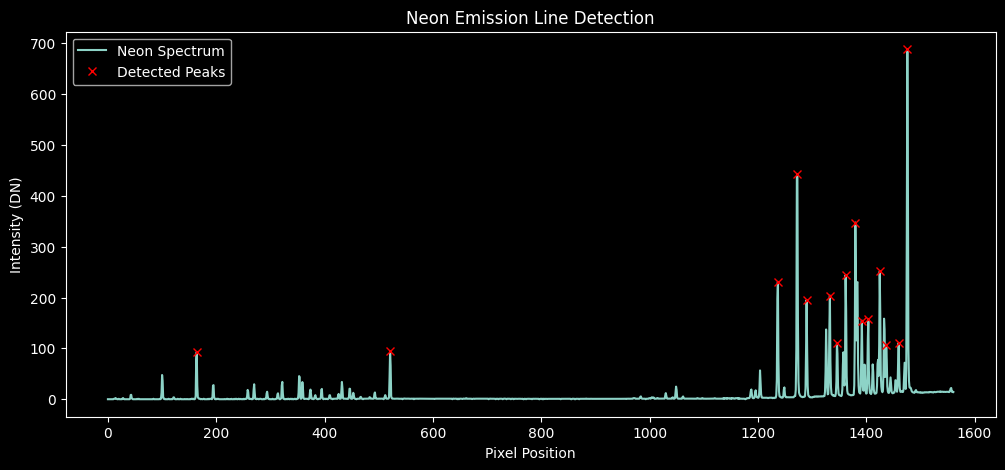

Detected peaks at pixels: [ 164  521 1237 1273 1290 1333 1346 1362 1380 1392 1404 1425 1437 1460
 1476]


In [54]:
from scipy.signal import find_peaks

# 1. Collapse to 1D
arc_1d = np.median(normalized_calibrated_crop_arc, axis=0)

# 2. Find peaks (adjust 'height' and 'distance' based on your noise levels)
# You want the sharp Neon spikes, not the tiny noise bumps.
peaks, properties = find_peaks(arc_1d, height=80, distance=10)

# 3. Plot to verify
plt.figure(figsize=(12, 5))
plt.plot(arc_1d, label='Neon Spectrum')
plt.plot(peaks, arc_1d[peaks], "x", color='red', label='Detected Peaks')
plt.title("Neon Emission Line Detection")
plt.xlabel("Pixel Position")
plt.ylabel("Intensity (DN)")
plt.legend()
plt.show()

# Print the pixel positions found
print(f"Detected peaks at pixels: {peaks}")

We reference:

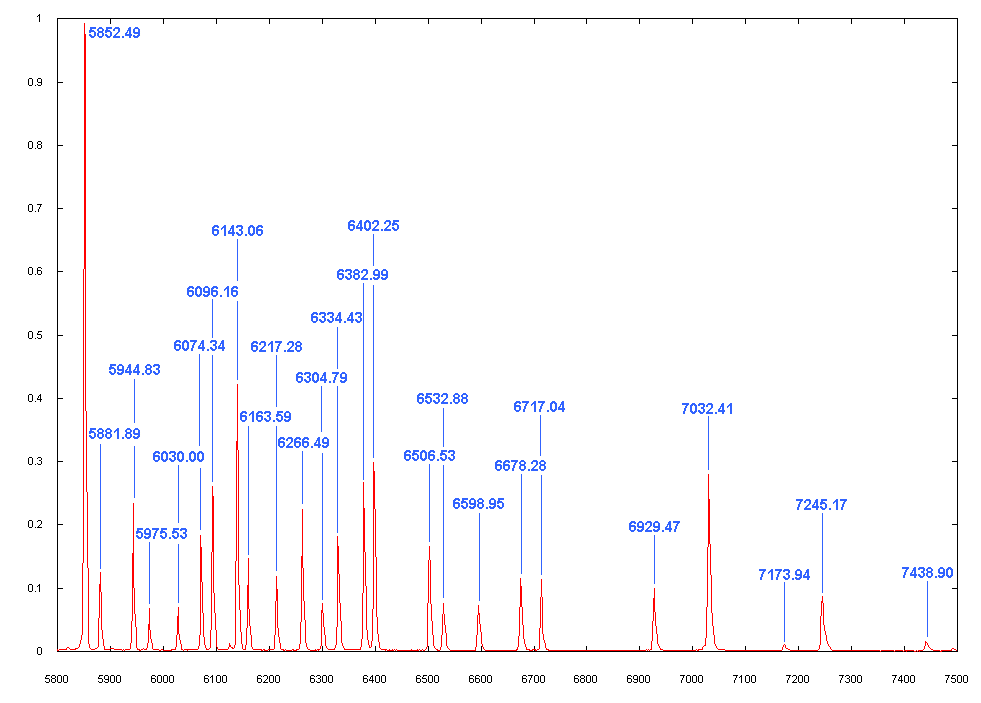

Now that we have the wavelength relative to the pixel position, we will plot it, find a best fit polynomial which will be our wavelength calibration.

In [64]:
import pandas as pd

#Detected Pixel Peaks
pixels = np.array([164, 521, 1273, 1380, 1476])

# referenced wavelength
wavelengths = np.array([5852.49, 6143.06, 6506.53, 6678.28, 7032.41])

# Calibration Table
calibration_table = pd.DataFrame({
    'Pixel Position': pixels,
    'Literature Wavelength (Å)': wavelengths
})
print("Wavelength Calibration Table:")
print(calibration_table)

#Derive the Calibration
coeffs = np.polyfit(pixels, wavelengths, 3)
poly_cal = np.poly1d(coeffs)

# Define the missing variables for your print statements:
total_coverage = poly_cal(1562) - poly_cal(0)
avg_dispersion = total_coverage / 1562

print(f"Total Spectral Coverage: {total_coverage:.2f} Angstroms")
print(f"Dispersion: {avg_dispersion:.4f} Angstroms per pixel")


Wavelength Calibration Table:
   Pixel Position  Literature Wavelength (Å)
0             164                    5852.49
1             521                    6143.06
2            1273                    6506.53
3            1380                    6678.28
4            1476                    7032.41
Total Spectral Coverage: 1876.20 Angstroms
Dispersion: 1.2012 Angstroms per pixel


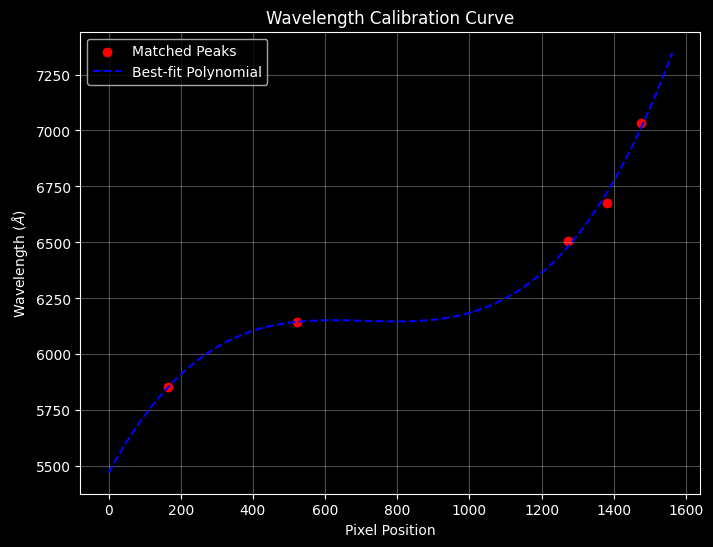

In [61]:
plt.figure(figsize=(8, 6))
plt.scatter(pixels, wavelengths, color='red', label='Matched Peaks')
x_range = np.linspace(0, 1562, 100)
plt.plot(x_range, poly_cal(x_range), 'b--', label='Best-fit Polynomial')
plt.xlabel("Pixel Position")
plt.ylabel("Wavelength ($\AA$)")
plt.title("Wavelength Calibration Curve")
plt.legend()
plt.grid(True, alpha=0.3)
plt.show()

4.4.7) We now plot the calibrated spectrum with labelings of Neon emmission lines

4.48)
Total Spectral Coverage: 1876.20 Angstroms
Dispersion: 1.2012 Angstroms per pixel

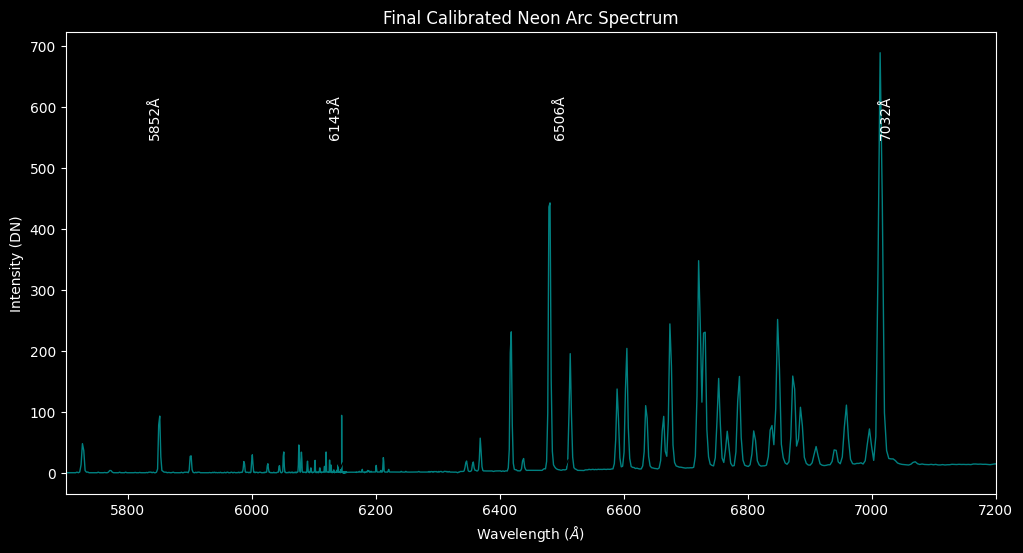

In [63]:
# Create the new X-axis in Angstroms
all_pixels = np.arange(len(arc_1d))
calibrated_x = poly_cal(all_pixels)

# Plot the final result
plt.figure(figsize=(12, 6))
plt.plot(calibrated_x, arc_1d, color='teal', lw=1)

# Labelling the Neon lines
line_labels = {5852.49: '5852Å', 6143.06: '6143Å', 6506.53: '6506Å', 7032.41: '7032Å'}
for wave, label in line_labels.items():
    plt.annotate(label, xy=(wave, arc_1d[np.abs(calibrated_x - wave).argmin()]),
                 xytext=(wave-20, arc_1d.max()*0.8),
                 arrowprops=dict(arrowstyle='->', color='black'),
                 rotation=90)

plt.xlabel("Wavelength ($\AA$)")
plt.ylabel("Intensity (DN)")
plt.title("Final Calibrated Neon Arc Spectrum")
plt.xlim(5700, 7200) # Zooming in on the relevant range
plt.show()

4.5) To calibrate the scientific image, we would need to do $$S_{calibrated} = \frac{(S_{raw} - \text{Master Dark})}{\text{Master Flat}}$$
The dark and bias frames does not need to be taken with the same telescope but the camera must stay the same. The bias frame is a just a electornical offset that is determined by the camera's settings and temperature (since the exposure time is very short, there isn't a huge dependency on temperature). Similarly, dark frames are entirely dependent on the camera, exposure time and temperature. Therefore, both of them can be taken the next day. The flats fields however, need to have the same telescope and taken on the same day. One thing that flat fields detect is dust spots on the telescope. Therefore, if one change the telescope or even change the filter, the dust patterns will not (usually) be the same.

#5) The object of our choice was Bode's Galaxy. Our observation date was 2/10/2026 and the specifications are:


Bode’s Galaxy (Messier 81, NGC 3031):

Coordinates: 09 55 33.173, +69 03 55


Apparent Size: 26.9' x 14.1'


Apparent Magnitude: 6.94
s
The visibility is shown by the following image created by STARALT:

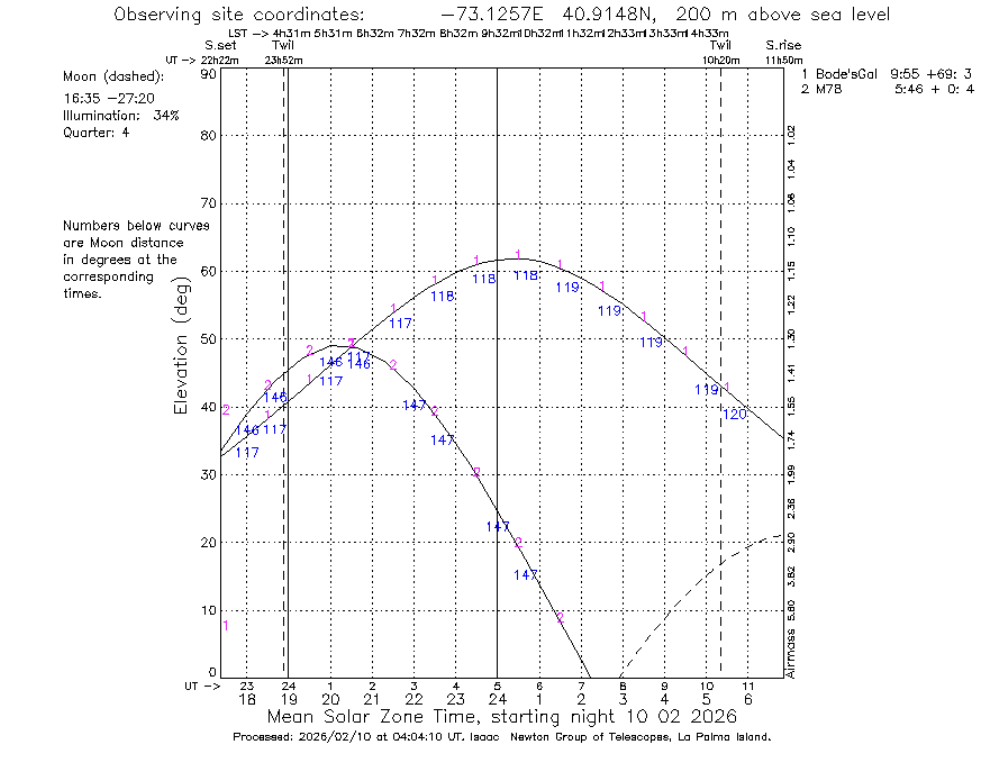



We took 4 sets of pictures with the blue, infared, red and visual filter:

Blue:    5 images, 60 seconds

Infared: 10 images, 30 seconds

Red:     5 images, 60 seconds,

Visual:  5 images, 30 seconds.

We took flats corresponding to each of the filters and also sets of darks that match the exposure time for all the flats and science images (temperature for every frame is between [-1,1]C

We calibrate the flats like usual by subtracting the corresponding darks and normalizing using the median of the flat stacks.

In [34]:
def master_subtractor(files_path_1, files_path_2):
    """
    Inputs:
        files_path_1: Glob string for first set (e.g., 'Flats/*.fits')
        files_path_2: Glob string for second set (e.g., 'Darks/*.fits')
    Output:
        The subtracted master array (Master1 - Master2)
    """
    # 1. Get the master of the first set using your existing function
    # We use [0] to only take the 'master' and ignore 'pixels' and 'stack'
    m1 = fits_file_stack(files_path_1)[0]

    # 2. Get the master of the second set
    m2 = fits_file_stack(files_path_2)[0]

    # 3. Subtract
    result = m1 - m2

    print(f"Subtraction complete. Shape: {result.shape}")
    return result

# For Blue filter
cal_flat_B = master_subtractor('Lab 1 Pretty Picture/Flat_B_20s_*.fits',
                               'Lab 1 Pretty Picture/Dark_20s_*.fits')

# For Red filter
cal_flat_R = master_subtractor('Lab 1 Pretty Picture/Flat_R_2s_*.fits',
                               'Lab 1 Pretty Picture/Dark_2s_*.fits')

#For visual filter

cal_flat_V = master_subtractor('Lab 1 Pretty Picture/Flat_V_5s_*.fits',
                               'Lab 1 Pretty Picture/Dark_5s_*.fits')

#For infared

cal_flat_I = master_subtractor('Lab 1 Pretty Picture/Flat_I_2s_*.fits',
                               'Lab 1 Pretty Picture/Dark_2s_*.fits')


Found 4 files
Stack shape: (4, 1044, 1562)
Found 10 files
Stack shape: (10, 1044, 1562)
Subtraction complete. Shape: (1044, 1562)
Found 4 files
Stack shape: (4, 1044, 1562)
Found 10 files
Stack shape: (10, 1044, 1562)
Subtraction complete. Shape: (1044, 1562)
Found 4 files
Stack shape: (4, 1044, 1562)
Found 10 files
Stack shape: (10, 1044, 1562)
Subtraction complete. Shape: (1044, 1562)
Found 4 files
Stack shape: (4, 1044, 1562)
Found 10 files
Stack shape: (10, 1044, 1562)
Subtraction complete. Shape: (1044, 1562)


In [35]:
norm_flat_B = cal_flat_B / np.median(cal_flat_B)
norm_flat_R = cal_flat_R / (np.median(cal_flat_R))
norm_flat_V = cal_flat_V / (np.median(cal_flat_V))
norm_flat_I = cal_flat_I / (np.median(cal_flat_I))


In [36]:
cal_jupiter_B_60s = master_subtractor('Lab 1 Pretty Picture/Jupiter_B_60s_*.fits', 'Lab 1 Pretty Picture/Dark_60s_*.fits') / norm_flat_B
cal_jupiter_I_30s = master_subtractor('Lab 1 Pretty Picture/Jupiter_I_30s_*.fits', 'Lab 1 Pretty Picture/Dark_30s_*.fits') / norm_flat_I
cal_jupiter_R_60s = master_subtractor('Lab 1 Pretty Picture/Jupiter_R_60s_*.fits', 'Lab 1 Pretty Picture/Dark_60s_*.fits') / norm_flat_R
cal_jupiter_V_60s = master_subtractor('Lab 1 Pretty Picture/Jupiter_V_60s_*.fits', 'Lab 1 Pretty Picture/Dark_60s_*.fits') / norm_flat_V

Found 5 files
Stack shape: (5, 1044, 1562)
Found 5 files
Stack shape: (5, 1044, 1562)
Subtraction complete. Shape: (1044, 1562)
Found 10 files
Stack shape: (10, 1044, 1562)
Found 10 files
Stack shape: (10, 1044, 1562)
Subtraction complete. Shape: (1044, 1562)
Found 5 files
Stack shape: (5, 1044, 1562)
Found 5 files
Stack shape: (5, 1044, 1562)
Subtraction complete. Shape: (1044, 1562)
Found 5 files
Stack shape: (5, 1044, 1562)
Found 5 files
Stack shape: (5, 1044, 1562)
Subtraction complete. Shape: (1044, 1562)


In [37]:
import os
from astropy.io import fits

# 1. Create the directory if it doesn't already exist
output_folder = 'calibrated_pretty_pictures'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)
    print(f"Created folder: {output_folder}")

# 2. Map your variables to the filenames
# Make sure these variable names match exactly what you used in your calibration cell
outputs = {
    'Jupiter_B_Calibrated.fits': cal_jupiter_B_60s,
    'Jupiter_V_Calibrated.fits': cal_jupiter_V_60s,
    'Jupiter_R_Calibrated.fits': cal_jupiter_R_60s,
    'Jupiter_I_Calibrated.fits': cal_jupiter_I_30s
}

# 3. Save each one into the new folder
for filename, data in outputs.items():
    # Construct the full path (e.g., 'calibrated_pretty_pictures/Jupiter_B_Calibrated.fits')
    full_path = os.path.join(output_folder, filename)

    # Create the FITS object and save
    hdu = fits.PrimaryHDU(data)
    hdu.writeto(full_path, overwrite=True)

    print(f"Successfully saved to: {full_path}")

Successfully saved to: calibrated_pretty_pictures\Jupiter_B_Calibrated.fits
Successfully saved to: calibrated_pretty_pictures\Jupiter_V_Calibrated.fits
Successfully saved to: calibrated_pretty_pictures\Jupiter_R_Calibrated.fits
Successfully saved to: calibrated_pretty_pictures\Jupiter_I_Calibrated.fits


Minimum value: -1234.95
Maximum value: 1168.47
Median value:  847.14


PhdGuide was not really working well on the day of the observation because of the clouds. Therefore, the images we took were not aligned. So instead of just stacking up science images and proceeding with the usual calibration steps, we first need to align the iamges together. I used phase cross correlation to do this. For each set of science image (I did this for the R, V , B set to simulate RGB) I calibrated each image (for each set) individually to erase any noise that will affect the alignment. Then I used a abritray image for each set and performed alignment that is contained within the set. After I stacked the aligned image for each set, I used the V filter master to align the R and B master, creating our final aligned calibrated sciene image for each set. (Most of these alignment codes is written up by GEMINI).

In [39]:
from skimage.registration import phase_cross_correlation
from scipy.ndimage import shift

In [40]:
import numpy as np
from astropy.io import fits
import glob
from skimage.registration import phase_cross_correlation
from scipy.ndimage import shift
import os
pp_master_dark_60s = fits_file_stack('Lab 1 Pretty Picture/Dark_60s_*.fits')[0]
def align_and_stack_band(file_pattern, master_dark, norm_flat):
    """
    Step 1 & 2: Calibrates individual frames and aligns them to the first frame
    of their own band to create a clean Master.
    """
    files = sorted(glob.glob(file_pattern))

    calibrated_list = []

    #INDIVIDUAL CALIBRATION
    for f in files:
        with fits.open(f) as hdul:
            # 1. Load and subtract dark, divide by normalized flat
            data = hdul[0].data.astype(float)
            cal = (data - master_dark) / norm_flat

            # 2. Subtract local background median to help the aligner "see" stars
            cal -= np.median(cal)
            calibrated_list.append(cal)

    # INTERNAL ALIGNMENT (Band-Level)
    # We use the first frame as the 'Local Reference'
    ref_frame = calibrated_list[0]
    aligned_band_frames = [ref_frame]

    print(f"Aligning {len(calibrated_list)} frames in {file_pattern}...")

    for i in range(1, len(calibrated_list)):
        # Calculate pixel shift (dy, dx) using cross-correlation
        # This finds where the 'trailing' patterns overlap best
        shifts, error, diffphase = phase_cross_correlation(ref_frame, calibrated_list[i])

        # Apply the shift to the frame
        aligned = shift(calibrated_list[i], shift=shifts, mode='constant', cval=0)
        aligned_band_frames.append(aligned)

    #STACKING
    # Median stack to remove cosmic rays and random noise
    master_band = np.median(np.array(aligned_band_frames), axis=0)
    return master_band

# STEP 1: CREATE BAND MASTERS
# We assume you already have norm_flat_B, V, R and the master_dark_60s ready
master_B = align_and_stack_band('Lab 1 Pretty Picture/Jupiter_B_60s_*.fits', pp_master_dark_60s, norm_flat_B)
master_V = align_and_stack_band('Lab 1 Pretty Picture/Jupiter_V_60s_*.fits', pp_master_dark_60s, norm_flat_V)
master_R = align_and_stack_band('Lab 1 Pretty Picture/Jupiter_R_60s_*.fits', pp_master_dark_60s, norm_flat_R)

# STEP 2: INTER-BAND ALIGNMENT (Global Anchor)
# We pick Master V as the "Anchor" because it usually has the best star definition
print("Final alignment: Matching B and R Masters to the V Master...")

# Align Master B to Master V
shift_B, _, _ = phase_cross_correlation(master_V, master_B)
final_B = shift(master_B, shift=shift_B)

# Align Master R to Master V
shift_R, _, _ = phase_cross_correlation(master_V, master_R)
final_R = shift(master_R, shift=shift_R)

#STEP 3: PREPARE FOR RGB
# Now final_B, master_V, and final_R are perfectly registered!
# We set final_V to the anchor name for consistency
final_V = master_V

Found 5 files
Stack shape: (5, 1044, 1562)
Aligning 5 frames in Lab 1 Pretty Picture/Jupiter_B_60s_*.fits...
Aligning 5 frames in Lab 1 Pretty Picture/Jupiter_V_60s_*.fits...
Aligning 5 frames in Lab 1 Pretty Picture/Jupiter_R_60s_*.fits...
Final alignment: Matching B and R Masters to the V Master...


The B master still had a trail of fog chasing the stars so instead of using internal alignment, I just aligned each blue frame using the V master as the reference frame from the start.

In [41]:
# Try aligning individual Blue frames directly to the high-quality Master V
def fix_blue_alignment(blue_glob, master_v_anchor, master_dark, norm_flat_b):
    files = sorted(glob.glob(blue_glob))
    aligned_frames = []

    print("Re-aligning Blue frames using Master V as the anchor...")
    for f in files:
        with fits.open(f) as hdul:
            data = (hdul[0].data.astype(float) - master_dark) / norm_flat_b
            data -= np.median(data)

            # Match this specific blue frame to the Master V 'map'
            shifts, error, _ = phase_cross_correlation(master_v_anchor, data)
            print(f"  Fixed Shift for {os.path.basename(f)} -> dy: {shifts[0]:.2f}, dx: {shifts[1]:.2f}")

            aligned = shift(data, shift=shifts)
            aligned_frames.append(aligned)

    return np.median(np.array(aligned_frames), axis=0)

# Run the fix
final_B = fix_blue_alignment('Lab 1 Pretty Picture/Jupiter_B_60s_*.fits', master_V, pp_master_dark_60s, norm_flat_B)

Re-aligning Blue frames using Master V as the anchor...
  Fixed Shift for Jupiter_B_60s_-1C_20260213_004531.fits -> dy: 94.00, dx: 48.00
  Fixed Shift for Jupiter_B_60s_-1C_20260213_004632.fits -> dy: 83.00, dx: 43.00
  Fixed Shift for Jupiter_B_60s_0C_20260213_004328.fits -> dy: 111.00, dx: 56.00
  Fixed Shift for Jupiter_B_60s_0C_20260213_004430.fits -> dy: 102.00, dx: 52.00
  Fixed Shift for Jupiter_B_60s_0C_20260213_004733.fits -> dy: 75.00, dx: 39.00


Now all that is left is to display each image as their assigned colors, remove the background by dividing by the median of each color channel, and create the final RGB image.

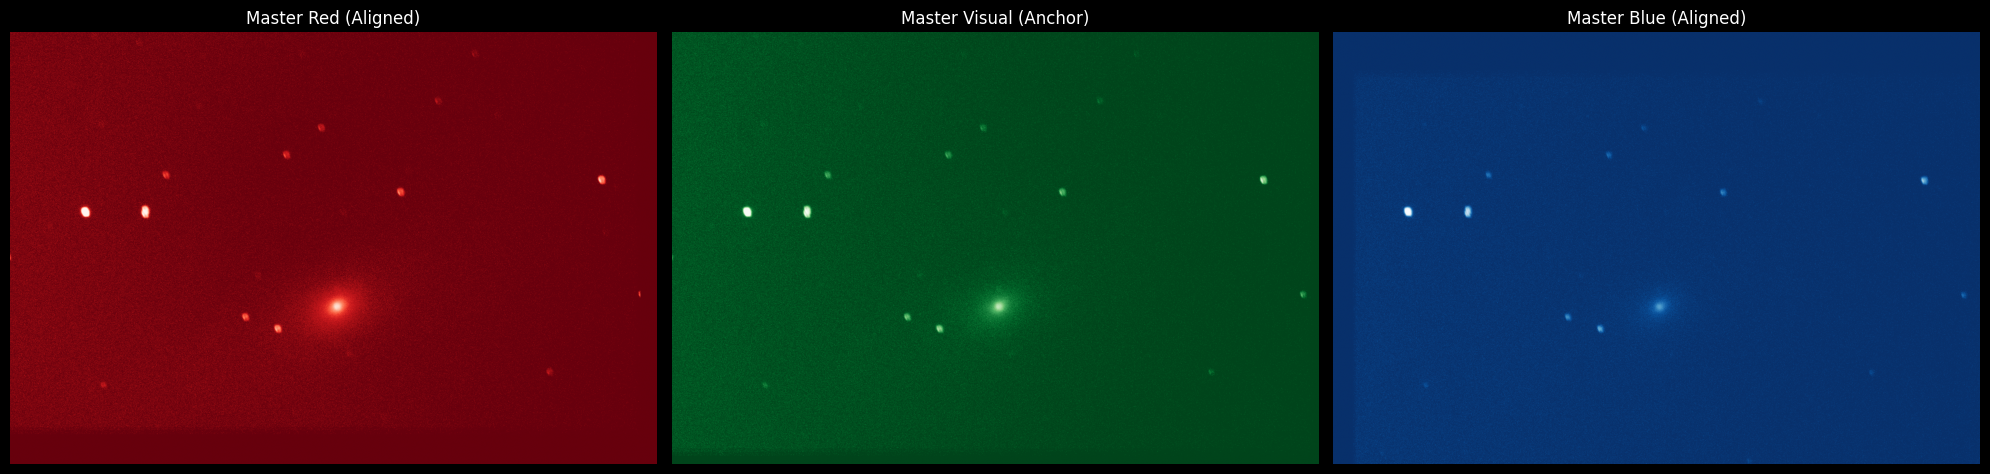

In [42]:
import matplotlib.pyplot as plt
from astropy.visualization import make_lupton_rgb, AsinhStretch, ImageNormalize

# Create a helper to stretch the data for our eyes
norm = ImageNormalize(vmin=0, vmax=500, stretch=AsinhStretch())

fig, axes = plt.subplots(1, 3, figsize=(20, 7))

# Display Red
axes[0].imshow(final_R, norm=norm, cmap='Reds_r')
axes[0].set_title("Master Red (Aligned)")

# Display Visual (Green)
axes[1].imshow(final_V, norm=norm, cmap='Greens_r')
axes[1].set_title("Master Visual (Anchor)")

# Display Blue
axes[2].imshow(final_B, norm=norm, cmap='Blues_r')
axes[2].set_title("Master Blue (Aligned)")

for ax in axes:
    ax.axis('off')

plt.tight_layout()
plt.show()

In [43]:
from astropy.io import fits
import os

output_folder = 'calibrated_aligned_pretty_pictures'
if not os.path.exists(output_folder):
    os.makedirs(output_folder)

# We save them with "Fixed" in the name so you know which one worked
final_outputs = {
    'M81_Aligned_R.fits': final_R,
    'M81_Aligned_V.fits': master_V,
    'M81_Aligned_B_Fixed.fits': final_B
}

for filename, data in final_outputs.items():
    full_path = os.path.join(output_folder, filename)
    hdu = fits.PrimaryHDU(data)
    hdu.writeto(full_path, overwrite=True)
    print(f"Saved: {full_path}")

Saved: calibrated_aligned_pretty_pictures\M81_Aligned_R.fits
Saved: calibrated_aligned_pretty_pictures\M81_Aligned_V.fits
Saved: calibrated_aligned_pretty_pictures\M81_Aligned_B_Fixed.fits


C:\Users\HP\AppData\Local\SageMath 9.3\.venv\Lib\site-packages\astropy\visualization\lupton_rgb.py:645: RuntimeWarning: invalid value encountered in divide
  fInorm = np.where(Int <= 0, 0, np.true_divide(fI, Int))


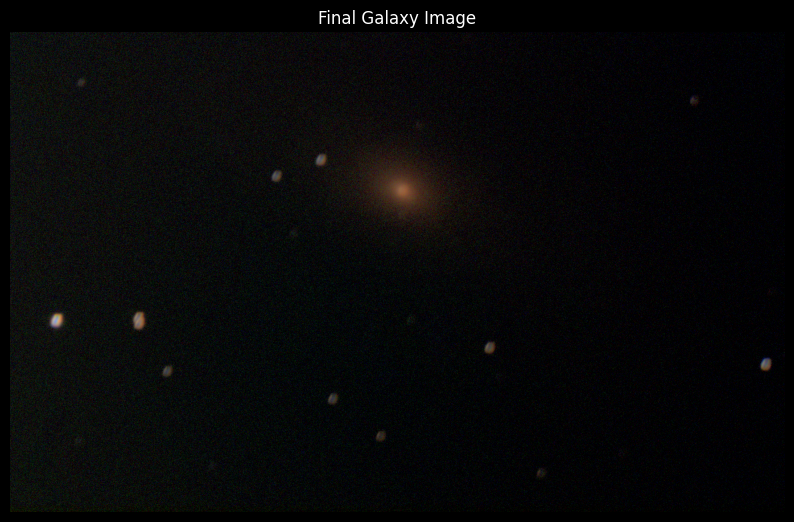

Pretty picture saved as final_galaxy_pretty_picture.png


In [44]:

import numpy as np
import matplotlib.pyplot as plt
from astropy.visualization import make_lupton_rgb

# 1. LOAD THE ALIGNED CHANNELS

R = final_R.copy()
G = master_V.copy()  # using V band as Green
B = final_B.copy()

# 2. REMOVE SKY BACKGROUND

R -= np.median(R)
G -= np.median(G)
B -= np.median(B)

# clip negative values
R = np.clip(R, 0, None)
G = np.clip(G, 0, None)
B = np.clip(B, 0, None)

# 3. NORMALIZE CHANNELS
# (keeps colors balanced)

R = R / np.percentile(R, 99)
G = G / np.percentile(G, 99)
B = B / np.percentile(B, 99)

R*= 1.0
G*= 1.00
B*= 1.0

# 4. CREATE RGB IMAGE

rgb = make_lupton_rgb(R, G, B,
                      stretch=5,
                      Q=10)

# 5. CROP EDGES (alignment borders)

y, x = rgb.shape[:2]
rgb_crop = rgb[100:y - 100, 100:x - 100]

# 6. DISPLAY FINAL IMAGE

plt.figure(figsize=(10, 10))
plt.imshow(rgb_crop, origin='lower')
plt.title("Final Galaxy Image")
plt.axis('off')
plt.show()

# 7. SAVE FINAL IMAGE

plt.imsave("final_galaxy_pretty_picture.png", rgb_crop, origin='lower')

print("Pretty picture saved as final_galaxy_pretty_picture.png")